# Flood Control Projects — Stage 2: Exploratory Data Analysis
## Philippine Flood Control Projects Analysis

This notebook covers the second stage of the Python phase of the project: exploring the cleaned dataset to answer five questions.

1. **Scale and trend** — how many projects, how much total cost, and how spending changed by year
2. **Geography** — which regions and provinces receive the most funding
3. **Contractors** — which contractors hold the most contracts and the highest total value
4. **Project duration** — how long projects take from start to completion, and how this differs by type of work and region
5. **Type and location** — what types of work are built and where

**Input:** `data/flood_control_clean.xlsx`, the output of `01_load_clean.ipynb`.

**Output of this notebook:** findings used for the README and to plan the Power BI dashboard.

In [8]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_excel("../data/flood_control_clean.xlsx")
print(df.shape)

(9827, 26)


## 1. Scale and trend

How many projects are there, what is their total contract cost, and how has
spending changed by year?

Spending by year uses `InfraYear`. For multi-year contracts, only the earliest
year was kept during cleaning, so the full contract cost is attributed to that
first year.

In [5]:
print("Total projects:", len(df))
print(f"Total contract cost: ₱{df['ContractCost'].sum() / 1e9:,.2f}B")
print(f"Average cost per project: ₱{df['ContractCost'].mean() / 1e6:,.1f}M")
print(f"Median cost per project: ₱{df['ContractCost'].median() / 1e6:,.1f}M")

Total projects: 9827
Total contract cost: ₱545.43B
Average cost per project: ₱55.5M
Median cost per project: ₱49.0M


In [6]:
by_year = (
    df.groupby("InfraYear")
    .agg(projects=("ProjectID", "count"),
         total_cost_B=("ContractCost", lambda s: s.sum() / 1e9))
    .round(2)
)
by_year

,projects,total_cost_B
InfraYear,,
2018,7,0.73
2019,3,0.34
2020,35,2.28
2021,593,28.50
2022,3334,164.26
2023,3466,203.22
2024,2354,144.65
2025,35,1.45


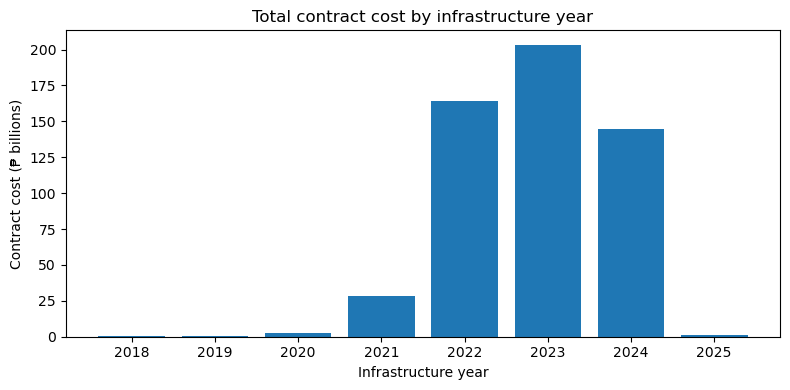

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_year.index.astype(str), by_year["total_cost_B"])
ax.set_title("Total contract cost by infrastructure year")
ax.set_xlabel("Infrastructure year")
ax.set_ylabel("Contract cost (₱ billions)")
plt.tight_layout()
plt.show()

### Findings

- The dataset has 9,827 flood control projects with a total contract cost of
  ₱545.43B. The average project costs ₱55.5M and the median is ₱49.0M.
- Spending is concentrated in 2022–2024, which together account for about 94%
  of the total cost. It peaked in 2023 at ₱203.2B across 3,466 projects.
- Years before 2021 have very few projects (45 in total across 2018–2020).
- 2025 has only 35 projects. The source data was last updated in September
  2025, so this year may not be fully represented.

## 2. Geography

Which regions and provinces receive the most funding?

Totals use `ContractCost` and are not adjusted for population, land area, or
flood exposure.

In [10]:
by_region = (
    df.groupby("Region")
    .agg(projects=("ProjectID", "count"),
         total_cost_B=("ContractCost", lambda s: s.sum() / 1e9))
    .round(2)
    .sort_values("total_cost_B", ascending=False)
)
by_region["share_pct"] = (
    by_region["total_cost_B"] / by_region["total_cost_B"].sum() * 100
).round(1)
by_region

,projects,total_cost_B,share_pct
Region,,,
Region III,1617,98.01,18.0
National Capital Region,1057,52.57,9.6
Region V,863,49.61,9.1
Region IV-A,828,39.96,7.3
Region I,851,39.32,7.2
Region II,626,36.30,6.7
Region VII,614,36.13,6.6
Region IV-B,498,34.96,6.4
Region X,428,27.05,5.0


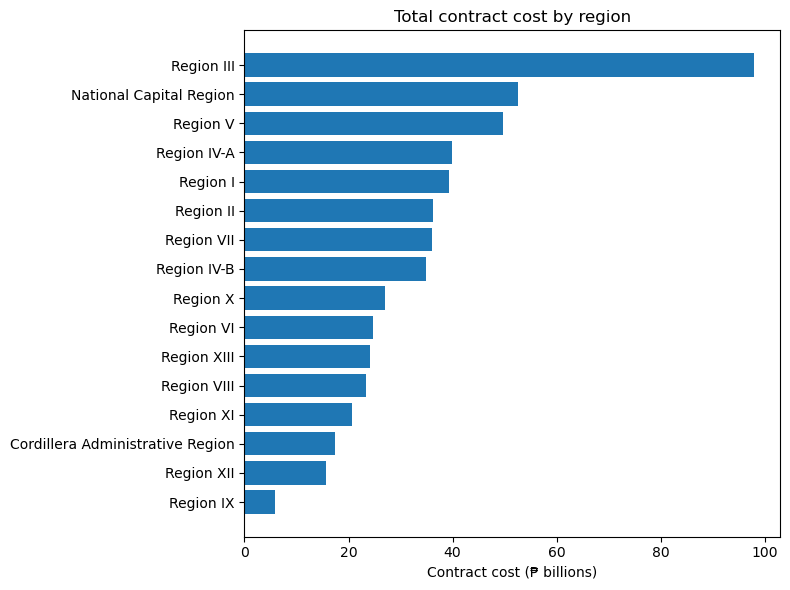

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(by_region.index[::-1], by_region["total_cost_B"][::-1])
ax.set_title("Total contract cost by region")
ax.set_xlabel("Contract cost (₱ billions)")
plt.tight_layout()
plt.show()

In [12]:
by_province = (
    df.groupby("Province")
    .agg(projects=("ProjectID", "count"),
         total_cost_B=("ContractCost", lambda s: s.sum() / 1e9))
    .round(2)
    .sort_values("total_cost_B", ascending=False)
)

top10 = by_province.head(10)
share_top10 = top10["total_cost_B"].sum() / by_province["total_cost_B"].sum() * 100
print(f"Top 10 provinces: {share_top10:.1f}% of total contract cost")
top10

Top 10 provinces: 37.1% of total contract cost


,projects,total_cost_B
Province,,
BULACAN,668,43.75
CEBU,414,26.61
ISABELA,341,22.92
TARLAC,258,18.58
CAMARINES SUR,251,17.57
ALBAY,273,16.17
CITY OF MANILA,215,14.46
PAMPANGA,292,14.31
LEYTE,261,14.16


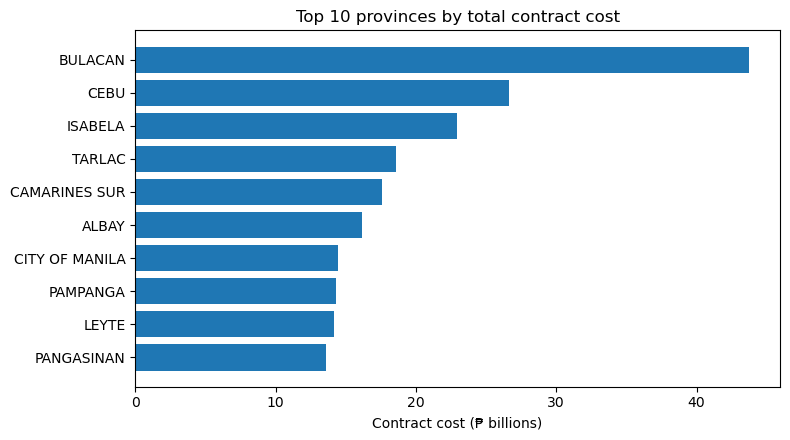

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index[::-1], top10["total_cost_B"][::-1])
ax.set_title("Top 10 provinces by total contract cost")
ax.set_xlabel("Contract cost (₱ billions)")
plt.tight_layout()
plt.show()

### Findings

- Region III has the highest total contract cost at ₱98.0B (18.0% of the total)
  across 1,617 projects, followed by the National Capital Region (₱52.6B, 9.6%)
  and Region V (₱49.6B, 9.1%).
- Region IX has the lowest total at ₱5.8B (1.1%) across 132 projects.
- Bulacan is the top province at ₱43.8B across 668 projects, about 8% of the
  national total, followed by Cebu (₱26.6B) and Isabela (₱22.9B).
- The top 10 provinces account for 37.1% of total contract cost.

## 3. Contractors

Which contractors hold the most contracts, and which have the highest total
contract value?

Contractors are counted by their name exactly as listed. Joint ventures are
written as "COMPANY A / COMPANY B" and count as their own entry, and names are
not merged across different spellings or "(FORMERLY: ...)" variants.

In [14]:
by_contractor = (
    df.groupby("Contractor")
    .agg(contracts=("ContractID", "nunique"),
         projects=("ProjectID", "count"),
         total_cost_B=("ContractCost", lambda s: s.sum() / 1e9))
    .round(2)
)

print("Contractors:", len(by_contractor))
print("Contractors with only 1 contract:", (by_contractor["contracts"] == 1).sum())

Contractors: 2409
Contractors with only 1 contract: 1165


In [15]:
# Top 10 by number of contracts (ties broken by total cost)
top_contracts = by_contractor.sort_values(
    ["contracts", "total_cost_B"], ascending=False
).head(10)
top_contracts

,contracts,projects,total_cost_B
Contractor,,,
LEGACY CONSTRUCTION CORPORATION (FORMERLY: LEGACY CONSTRUCTION),113,114,8.27
QM BUILDERS,88,88,6.96
ALPHA & OMEGA GEN. CONTRACTOR & DEVELOPMENT CORP.,84,84,5.74
ST. TIMOTHY CONSTRUCTION CORPORATION,83,83,5.47
"SUNWEST, INC. (FORMERLY: SUNWEST CONSTRUCTION & DEVELOPMENT CORPORATION)",67,67,8.25
ROYAL CROWN MONARCH CONSTRUCTION & SUPPLIES CORP.,56,56,4.93
WAWAO BUILDERS,53,53,3.83
"L.R. TIQUI BUILDERS, INC.",52,52,4.56
CENTERWAYS CONSTRUCTION AND DEVELOPMENT INC.,52,63,3.93


In [16]:
# Top 10 by total contract cost
top_value = by_contractor.sort_values(
    ["total_cost_B", "contracts"], ascending=False
).head(10)

share_top10 = (
    df.groupby("Contractor")["ContractCost"].sum().nlargest(10).sum()
    / df["ContractCost"].sum() * 100
)
print(f"Top 10 contractors by value: {share_top10:.1f}% of total contract cost")
top_value

Top 10 contractors by value: 10.3% of total contract cost


,contracts,projects,total_cost_B
Contractor,,,
LEGACY CONSTRUCTION CORPORATION (FORMERLY: LEGACY CONSTRUCTION),113,114,8.27
"SUNWEST, INC. (FORMERLY: SUNWEST CONSTRUCTION & DEVELOPMENT CORPORATION)",67,67,8.25
QM BUILDERS,88,88,6.96
ALPHA & OMEGA GEN. CONTRACTOR & DEVELOPMENT CORP.,84,84,5.74
ST. TIMOTHY CONSTRUCTION CORPORATION,83,83,5.47
ROYAL CROWN MONARCH CONSTRUCTION & SUPPLIES CORP.,56,56,4.93
"L.R. TIQUI BUILDERS, INC.",52,52,4.56
MG SAMIDAN CONSTRUCTION,44,44,3.97
CENTERWAYS CONSTRUCTION AND DEVELOPMENT INC.,52,63,3.93


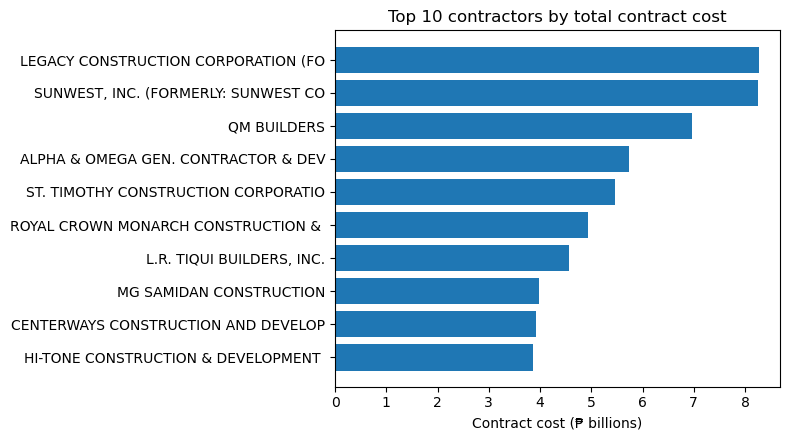

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = top_value.index.str[:35]   # shorten long names for the chart
ax.barh(labels[::-1], top_value["total_cost_B"][::-1])
ax.set_title("Top 10 contractors by total contract cost")
ax.set_xlabel("Contract cost (₱ billions)")
plt.tight_layout()
plt.show()

### Findings

- The dataset lists 2,409 contractor names. 1,165 of them (48.4%) hold only one
  contract.
- Legacy Construction Corporation has the most contracts (113) and the highest
  total contract cost (₱8.27B). Sunwest, Inc. is a close second by value
  (₱8.25B) with fewer contracts (67).
- The top 10 contractors by value account for 10.3% of total contract cost, and
  the largest single contractor accounts for about 1.5%, so contract value is
  spread across many contractors.
- Joint ventures (names written "A / B") account for 1,338 projects and about
  19% of total cost, and they are counted separately from their member
  companies. Per-company totals may therefore understate firms that also appear
  inside joint ventures.

## 4. Project duration

How long do projects take from start to completion, and does this differ by type
of work or region?

Duration is the number of days from `StartDate` to `CompletionDateActual`. The
median is used for comparisons because a small number of very long projects
pull the average up. Those long projects are kept in the data.

In [18]:
print(df["DurationDays"].describe().round(0))
print("Projects over 1,500 days:", (df["DurationDays"] > 1500).sum())

count    9827.0
mean      247.0
std       135.0
min        14.0
25%       161.0
50%       228.0
75%       299.0
max      2012.0
Name: DurationDays, dtype: float64
Projects over 1,500 days: 7


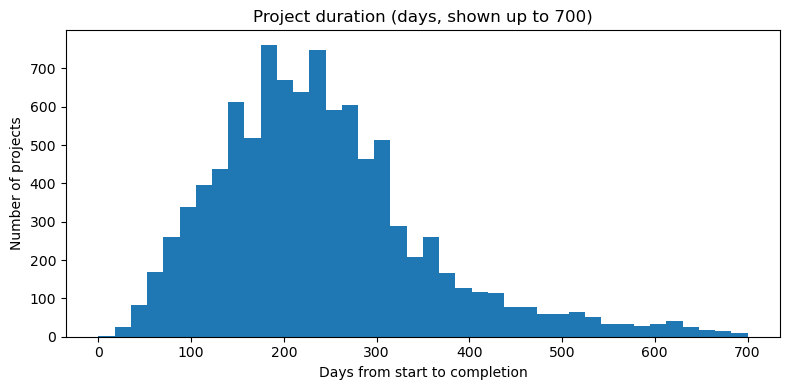

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["DurationDays"], bins=40, range=(0, 700))
ax.set_title("Project duration (days, shown up to 700)")
ax.set_xlabel("Days from start to completion")
ax.set_ylabel("Number of projects")
plt.tight_layout()
plt.show()

In [20]:
# Types of work with at least 30 projects (smaller groups are too few to compare)
by_type = (
    df.groupby("TypeofWork")["DurationDays"]
    .agg(projects="count", median_days="median")
    .query("projects >= 30")
    .sort_values("median_days", ascending=False)
)
by_type

,projects,median_days
TypeofWork,,
Construction of Revetment,733,266.0
Construction of Flood Mitigation Structure,6343,234.0
Rehabilitation / Major Repair of Flood Control Structure,646,218.5
Construction of Slope Protection Structure,739,211.0
Construction of Flood Mitigation Facility,169,209.0
Construction of Dike,224,200.0
Rehabilitation / Major Repair of Slope Protection Structure,41,193.0
Construction of Drainage Structure,678,179.0
Rehabilitation / Major Repair of Drainage Structure,215,179.0


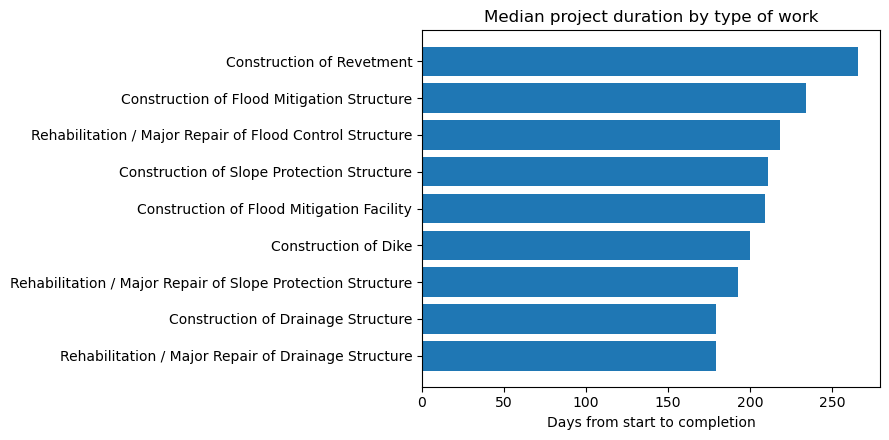

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(by_type.index[::-1], by_type["median_days"][::-1])
ax.set_title("Median project duration by type of work")
ax.set_xlabel("Days from start to completion")
plt.tight_layout()
plt.show()

In [22]:
by_region_days = (
    df.groupby("Region")["DurationDays"]
    .agg(projects="count", median_days="median")
    .sort_values("median_days", ascending=False)
)
by_region_days

,projects,median_days
Region,,
Region XIII,302,291.5
Region X,428,289.5
Region IX,132,266.5
Region XI,344,263.0
Region VI,502,259.0
National Capital Region,1057,239.0
Region VII,614,235.0
Region IV-B,498,230.5
Region IV-A,828,230.0


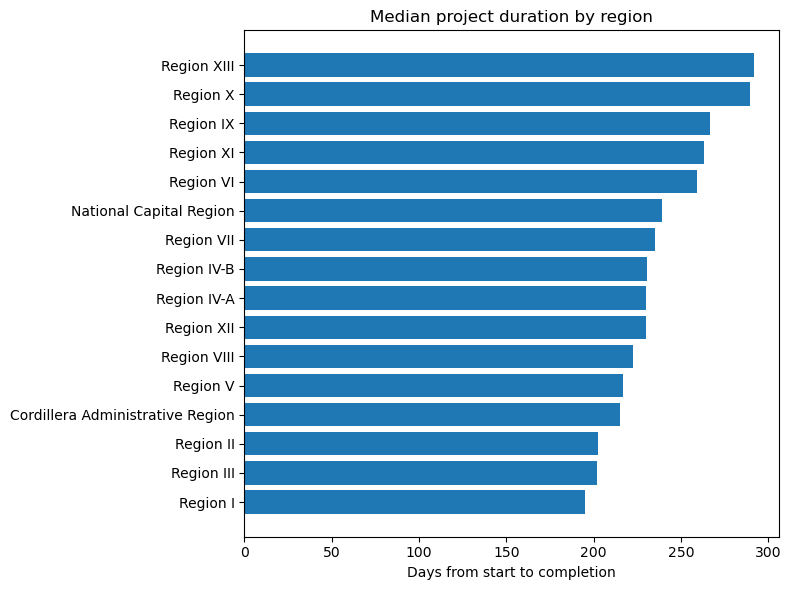

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(by_region_days.index[::-1], by_region_days["median_days"][::-1])
ax.set_title("Median project duration by region")
ax.set_xlabel("Days from start to completion")
plt.tight_layout()
plt.show()

### Findings

- The median project takes 228 days (about 7.5 months) from start to completion.
  The middle half of projects take between 161 and 299 days, and 90% finish
  within about 398 days.
- 7 projects took more than 1,500 days (over four years). They are kept in the
  data and do not affect the median.
- Among types of work with at least 30 projects, revetment construction has the
  longest median duration (266 days), while drainage structure projects have the
  shortest (179 days). Flood mitigation structures, the most common type
  (6,343 projects), have a median of 234 days.
- Median duration varies by region, from 195 days in Region I to 292 days in
  Region XIII, a gap of about 100 days.
- Duration is measured from the recorded start date to the recorded actual
  completion date. Differences between types and regions may reflect project
  size, contract terms, and local conditions, not performance.

## 5. Type and location

What types of flood control work are built, and where are the projects located?

In [24]:
by_work = (
    df.groupby("TypeofWork")
    .agg(projects=("ProjectID", "count"),
         total_cost_B=("ContractCost", lambda s: s.sum() / 1e9))
    .round(2)
    .sort_values("projects", ascending=False)
)
by_work["share_pct"] = (
    by_work["total_cost_B"] / by_work["total_cost_B"].sum() * 100
).round(1)
by_work

,projects,total_cost_B,share_pct
TypeofWork,,,
Construction of Flood Mitigation Structure,6343,363.22,66.6
Construction of Slope Protection Structure,739,44.01,8.1
Construction of Revetment,733,49.79,9.1
Construction of Drainage Structure,678,15.95,2.9
Rehabilitation / Major Repair of Flood Control Structure,646,35.03,6.4
Construction of Dike,224,16.15,3.0
Rehabilitation / Major Repair of Drainage Structure,215,4.66,0.9
Construction of Flood Mitigation Facility,169,12.02,2.2
Rehabilitation / Major Repair of Slope Protection Structure,41,1.91,0.4


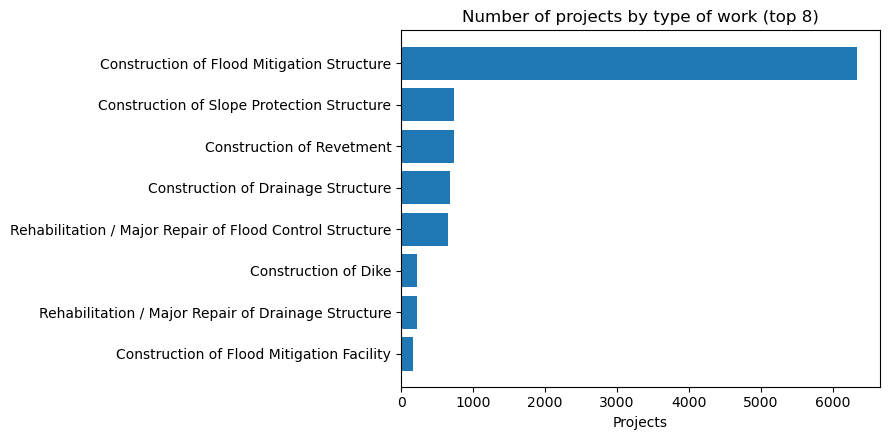

In [25]:
top_work = by_work.head(8)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top_work.index[::-1], top_work["projects"][::-1])
ax.set_title("Number of projects by type of work (top 8)")
ax.set_xlabel("Projects")
plt.tight_layout()
plt.show()

In [26]:
# Check that the coordinates are valid before plotting
print("Longitude range:", round(df["Longitude"].min(), 2), "to", round(df["Longitude"].max(), 2))
print("Latitude range:", round(df["Latitude"].min(), 2), "to", round(df["Latitude"].max(), 2))
print("Projects sharing exact coordinates with another project:",
      df.duplicated(["Latitude", "Longitude"]).sum())

Longitude range: 117.06 to 126.57
Latitude range: 5.77 to 20.46
Projects sharing exact coordinates with another project: 272


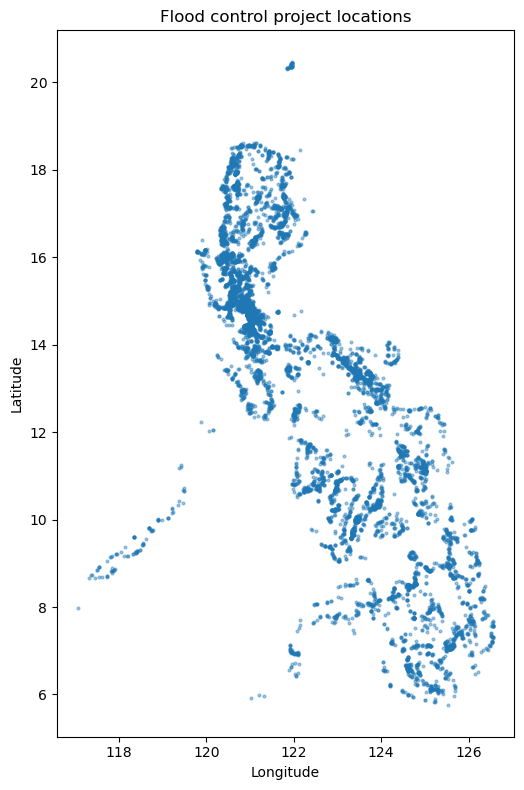

In [27]:
fig, ax = plt.subplots(figsize=(6, 8))
ax.scatter(df["Longitude"], df["Latitude"], s=4, alpha=0.4)
ax.set_title("Flood control project locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

### Findings

- Projects fall into 18 types of work. Construction of Flood Mitigation
  Structure dominates, with 6,343 projects (about 65% of all projects) and
  ₱363.2B (66.6% of total contract cost).
- Revetment construction (₱49.8B, 9.1%), slope protection construction
  (₱44.0B, 8.1%), and rehabilitation or major repair of flood control
  structures (₱35.0B, 6.4%) follow. The remaining 10 types each make up 0.9%
  of cost or less.
- All projects have valid coordinates that fall within the Philippines. 272
  projects share identical coordinates with another project, so some points
  overlap on the map.
- The map shows projects across the whole country, with the densest clusters
  in Luzon, which fits Region III and the National Capital Region leading in
  spending.